In [1]:
import os
from dotenv import load_dotenv
import json
import random
import matplotlib.pyplot as plt
import numpy as np
import asyncio
import pandas as pd

from benchmarklib import BenchmarkDatabase
from rbf import RandomBooleanFunctionTrial, RandomBooleanFunction
from benchmarklib.compilers import CompileType, XAGCompiler


from sqlalchemy import select, func
from sqlalchemy.orm import joinedload

In [2]:
benchmark_db = BenchmarkDatabase("rbf_nighthawk.db", RandomBooleanFunction, RandomBooleanFunctionTrial)

In [15]:
def get_raw_timing_data(db):
    data = {
        'XAG': {},
        'CLASSICAL_FUNCTION': {}
    }
    for num_vars in range(2, 21):
        for complexity in range(1, 21):
            data['XAG'][(num_vars, complexity)] = []
            data['CLASSICAL_FUNCTION'][(num_vars, complexity)] = []

    with db.session() as session:
        query = select(RandomBooleanFunction.num_vars, RandomBooleanFunction.complexity, RandomBooleanFunctionTrial.compiler_name, RandomBooleanFunctionTrial.extra_data).select_from(RandomBooleanFunctionTrial).join(RandomBooleanFunctionTrial.problem).where(RandomBooleanFunctionTrial.extra_data != None)
        result = session.execute(query).fetchall()
        for row in result:
            num_vars, complexity, compiler_name, extra_data = row
            compile_time = extra_data.get('compile_time', None)
            if compile_time is None:
                continue
            if compiler_name == 'XAG':
                data['XAG'][(num_vars, complexity)].append(compile_time)
            elif compiler_name == 'CLASSICAL_FUNCTION':
                data['CLASSICAL_FUNCTION'][(num_vars, complexity)].append(compile_time)

    return data

def average_timing_data(timing_data, mode='mean'):
    averages = {}
    for compiler in timing_data:
        averages[compiler] = {}
        for (num_vars, complexity) in timing_data[compiler]:
            if timing_data[compiler][(num_vars, complexity)]:
                if mode == 'mean':
                    averages[compiler][(num_vars, complexity)] = np.mean(timing_data[compiler][(num_vars, complexity)])
                elif mode == 'median':
                    averages[compiler][(num_vars, complexity)] = np.median(timing_data[compiler][(num_vars, complexity)])
    return averages


def plot_timing_difference(timing_data1, timing_data2, title, filepath=None):
    # num_vars_values = set(k[0] for k in timing_data1.keys())
    # complexity_values = set(k[1] for k in timing_data1.keys())
    num_vars_data = []
    complexity_data = []
    difference_data = []
    for (num_vars, complexity) in timing_data1.keys():
        num_vars_data.append(num_vars)
        complexity_data.append(complexity)
        difference_data.append(timing_data1[(num_vars, complexity)] - timing_data2[(num_vars, complexity)])

    df = pd.DataFrame({
        'num_vars': num_vars_data,
        'complexity': complexity_data,
        'diff': difference_data
    })
    grid = df.pivot(index='complexity', columns='num_vars', values='diff')
    grid = grid.sort_index(ascending=True)
    plt.figure(figsize=(12, 10))
    plt.pcolormesh(
        grid.columns, grid.index, grid.values,
        cmap='RdBu_r', shading='auto', vmin=-6, vmax=6
    )
    plt.xticks(np.arange(min(num_vars_data), max(num_vars_data) + 1, 1))
    plt.yticks(np.arange(min(complexity_data), max(complexity_data) + 1, 1))

    plt.xlabel('Number of Variables (n)')
    plt.ylabel('Complexity')
    plt.title(title)
    cbar = plt.colorbar()
    cbar.set_label(f'Difference in Compile Time', rotation=270, labelpad=15)
    if filepath is not None:
        plt.savefig(filepath, dpi=300, bbox_inches='tight')
    plt.show()

In [16]:
raw_data = get_raw_timing_data(benchmark_db)
data_means = average_timing_data(raw_data, mode='mean')
data_medians = average_timing_data(raw_data, mode='median')

In [17]:
import json
# strip complexity from the keys in the data dictionary
# to unify with other benchmarks
unified_data = {}
for compiler in raw_data:
    unified_data[compiler] = {}
    for key in raw_data[compiler].keys():
        num_vars, complexity = key
        unified_data[compiler][num_vars] = raw_data[compiler][num_vars, complexity]
with open("../shared/compile_time_data_rbf.json", "w") as f:
    f.write(json.dumps(unified_data))

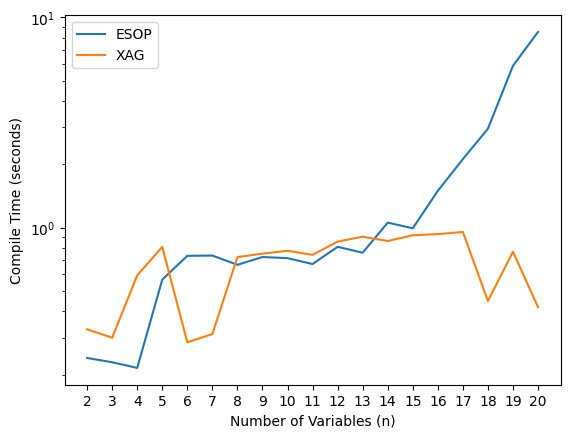

In [19]:
import numpy as np
compiler = "CLASSICAL_FUNCTION"
num_vars_data = range(2, 21)
timing_data = data_means
low_complexity_data = [timing_data[compiler][(num_vars, 1)] for num_vars in num_vars_data]
high_complexity_data = [timing_data[compiler][(num_vars, 20)] for num_vars in num_vars_data]
esop_mean_data = [np.mean([timing_data["CLASSICAL_FUNCTION"][(num_vars, complexity)] for complexity in range(1, 21) if timing_data["CLASSICAL_FUNCTION"][(num_vars, complexity)]]) for num_vars in num_vars_data]
xag_mean_data = [np.mean([timing_data["XAG"][(num_vars, complexity)] for complexity in range(1, 21) if timing_data["XAG"][(num_vars, complexity)]]) for num_vars in num_vars_data]
esop_median_data = [np.median([data_medians["CLASSICAL_FUNCTION"][(num_vars, complexity)] for complexity in range(1, 21) if data_medians["CLASSICAL_FUNCTION"][(num_vars, complexity)]]) for num_vars in num_vars_data]
xag_median_data = [np.median([data_medians["XAG"][(num_vars, complexity)] for complexity in range(1, 21) if data_medians["XAG"][(num_vars, complexity)]]) for num_vars in num_vars_data]
# plt.plot(num_vars_data, low_complexity_data, label='Low Complexity')
# plt.plot(num_vars_data, high_complexity_data, label='High Complexity')
plt.plot(num_vars_data, esop_mean_data, label='ESOP')
plt.plot(num_vars_data, xag_mean_data, label='XAG')
plt.xticks(num_vars_data)
plt.xlabel('Number of Variables (n)')
plt.ylabel('Compile Time (seconds)')
plt.yscale('log')
plt.legend()
plt.savefig('plots/RBF_timing_results_mean.png')
plt.show()

In [7]:
esop_median_data = []
xag_median_data = []
for num_vars in num_vars_data:
    esop_median_data.append(np.median(np.concatenate([raw_data['CLASSICAL_FUNCTION'][(num_vars, complexity)] for complexity in range(1, 21)])))
    xag_median_data.append(np.median(np.concatenate([raw_data['XAG'][(num_vars, complexity)] for complexity in range(1, 21)])))

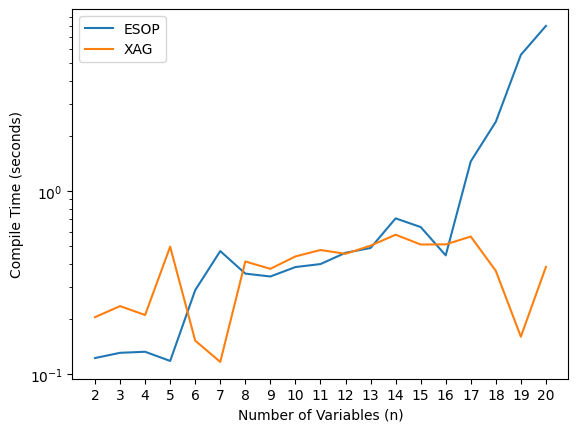

In [20]:
plt.plot(num_vars_data, esop_median_data, label='ESOP')
plt.plot(num_vars_data, xag_median_data, label='XAG')
plt.xticks(num_vars_data)
plt.xlabel('Number of Variables (n)')
plt.ylabel('Compile Time (seconds)')
plt.yscale('log')
plt.title('')
plt.legend()
plt.savefig('plots/RBF_timing_results_median.png')
plt.show()

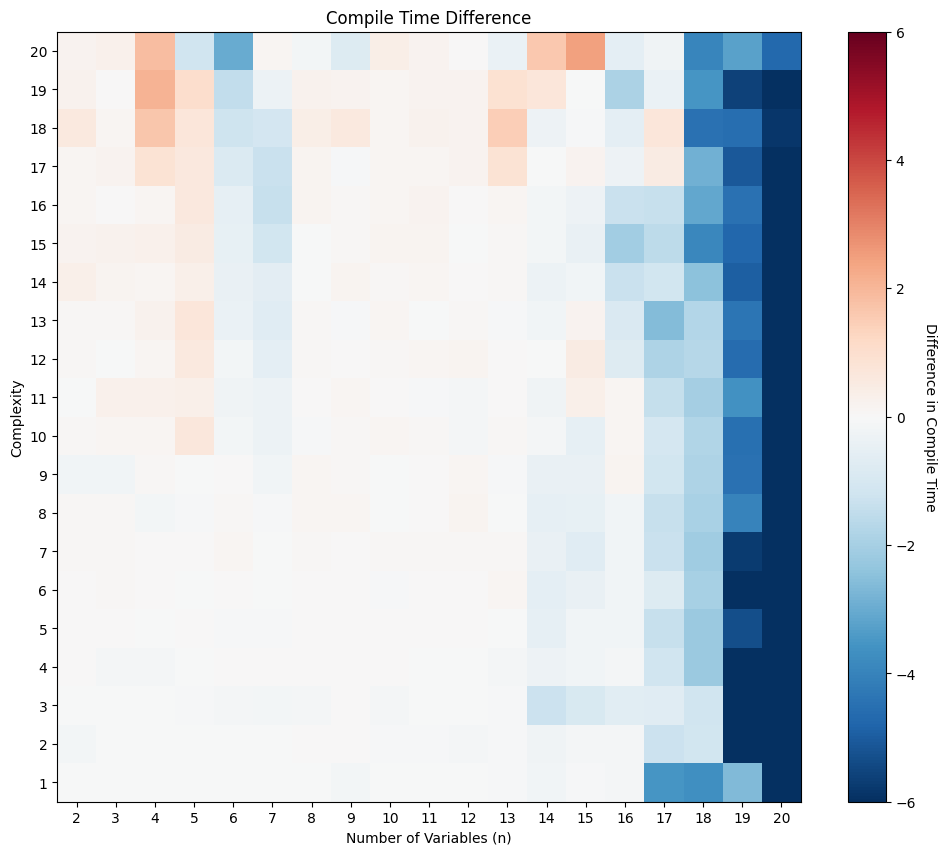

In [9]:
plot_timing_difference(data['XAG'], data['CLASSICAL_FUNCTION'], 'Compile Time Difference', 'plots/RBF_timing_difference.png')

In [ ]:
def print_latex_table(averages):
    print("\\begin{tabular}{|c|c|c|}")
    print("\\hline")
    print("Number of Variables & Complexity & ESOP Time & XAG Time\\\\")
    print("\\hline")
    for (num_vars, complexity) in averages['XAG']:
        xag_avg = averages['XAG'][(num_vars, complexity)]
        classical_avg = averages['CLASSICAL_FUNCTION'][(num_vars, complexity)]
        print(f"{num_vars} & {complexity} & {classical_avg:.3f} & {xag_avg:.3f} \\\\")
    print("\\hline")
    print("\\end{tabular}")
